# 05 · CKD · Chronic Kidney Disease Pipeline & Cross-Dataset Generalization

**Project:** Multimodal AI-based multi-disease clinical decision support system  
**Author:** Member 2 (CVD and CKD)  

**Goals of this notebook:**
1. Load and clean **UCI 336** (Chronic Kidney Disease, $N=400$, 24 features) and **UCI 857** (Risk Factor Prediction of Chronic Kidney Disease, $N=200$, 28 features) with zero data leakage.
2. Train and calibrate clinical tabular models (`LogReg`, `RandomForest`, `XGBoost`) with 5-fold CV and held-out test evaluation.
3. Evaluate **missing-data robustness** and **cross-dataset generalization** (`UCI 336` $\leftrightarrow$ `UCI 857`) on overlapping clinical features.
4. Implement **lab-vs-history conflict detection**, **reliability scoring**, **renal investigation suggestions**, and **SHAP explanations**.
5. Save `ckd_models.joblib` and export `ckd_assess()` matching the shared API JSON contract.


In [2]:
!pip install -q ucimlrepo shap xgboost

import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

warnings.filterwarnings("ignore")

from google.colab import drive
drive.mount("/content/drive")

DRIVE     = "/content/drive/MyDrive/cdss_data"
RAW       = f"{DRIVE}/raw/uci_ckd"
PROC      = f"{DRIVE}/processed/uci_ckd"
RES       = f"{DRIVE}/results/ckd"
MODEL_DIR = f"{DRIVE}/processed/models/ckd"
for d in [RAW, PROC, RES, MODEL_DIR]:
    os.makedirs(d, exist_ok=True)

SEED = 42
np.random.seed(SEED)

Mounted at /content/drive


## 1. Load & Clean UCI 336 and UCI 857

- **UCI 336 (Chronic Kidney Disease, Apollo Hospitals India):** 400 patients, 24 clinical/lab attributes (`age`, `bp`, `sg`, `al`, `su`, `rbc`, `pc`, `pcc`, `ba`, `bgr`, `bu`, `sc`, `sod`, `pot`, `hemo`, `pcv`, `wc`, `rc`, `htn`, `dm`, `cad`, `appet`, `pe`, `ane`). Known raw file quirks include trailing tabs (`ckd\t`, `\t?`) and string-encoded numbers (`pcv`, `wc`, `rc`).
- **UCI 857 (Risk Factor Prediction of Chronic Kidney Disease, Enam Medical College Bangladesh):** 200 patients with discretized clinical ranges (e.g., `'12 - 20'`, `'< 12'`, `'1.020'`). We parse interval strings into numeric midpoints so both datasets share continuous clinical representations for cross-dataset generalization.

In [3]:
from ucimlrepo import fetch_ucirepo


def clean_str_series(s):
    return (s.astype(str)
             .str.replace("\t", "", regex=False)
             .str.strip()
             .replace({"?": np.nan, "nan": np.nan, "None": np.nan, "": np.nan}))


def parse_range_to_numeric(val):
    """Convert numeric strings or range bins like '12 - 20', '< 12', '>= 1.020' to float midpoints."""
    if pd.isna(val):
        return np.nan
    s = str(val).replace("\t", "").strip()
    if s in ("", "?", "nan", "None"):
        return np.nan
    try:
        return float(s)
    except ValueError:
        pass
    nums = [float(x) for x in re.findall(r"-?\d+\.?\d*", s)]
    if len(nums) >= 2:
        return float(np.mean(nums[:2]))
    if len(nums) == 1:
        return float(nums[0])
    return np.nan


def load_uci_336():
    cache_csv = f"{RAW}/uci_336_raw.csv"
    if os.path.exists(cache_csv):
        df = pd.read_csv(cache_csv)
    else:
        ds = fetch_ucirepo(id=336)
        df = pd.concat([ds.data.features, ds.data.targets], axis=1)
        df.to_csv(cache_csv, index=False)

    df.columns = [c.strip().lower() for c in df.columns]
    for c in df.columns:
        if df[c].dtype == object:
            df[c] = clean_str_series(df[c])

    # Target: 'ckd' -> 1, 'notckd' -> 0
    y_col = "class" if "class" in df.columns else df.columns[-1]
    df["target"] = df[y_col].str.lower().map({"ckd": 1, "notckd": 0})
    df = df.dropna(subset=["target"]).copy()
    df["target"] = df["target"].astype(int)

    num_cols = ["age", "bp", "sg", "al", "su", "bgr", "bu", "sc", "sod", "pot", "hemo", "pcv", "wc", "rc"]
    bin_map = {
        "rbc": {"normal": 0, "abnormal": 1},
        "pc": {"normal": 0, "abnormal": 1},
        "pcc": {"notpresent": 0, "present": 1},
        "ba": {"notpresent": 0, "present": 1},
        "htn": {"no": 0, "yes": 1},
        "dm": {"no": 0, "yes": 1},
        "cad": {"no": 0, "yes": 1},
        "appet": {"good": 0, "poor": 1},
        "pe": {"no": 0, "yes": 1},
        "ane": {"no": 0, "yes": 1},
    }
    for c in num_cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    for c, mp in bin_map.items():
        if c in df.columns:
            df[c] = df[c].str.lower().map(mp)

    keep_cols = [c for c in num_cols + list(bin_map.keys()) if c in df.columns]
    return df[keep_cols + ["target"]].reset_index(drop=True)


def load_uci_857():
    cache_csv = f"{RAW}/uci_857_raw.csv"
    if os.path.exists(cache_csv):
        df = pd.read_csv(cache_csv)
    else:
        ds = fetch_ucirepo(id=857)
        df = pd.concat([ds.data.features, ds.data.targets], axis=1)
        df.to_csv(cache_csv, index=False)

    df.columns = [c.strip().lower() for c in df.columns]
    for c in df.columns:
        if df[c].dtype == object:
            df[c] = clean_str_series(df[c])

    y_col = "class" if "class" in df.columns else df.columns[-1]
    df["target"] = df[y_col].str.lower().map({"ckd": 1, "notckd": 0, "1": 1, "0": 0})
    df = df.dropna(subset=["target"]).copy()
    df["target"] = df["target"].astype(int)

    # Map UCI 857 columns onto UCI 336 canonical names where overlapping
    rename_map = {
        "bp (diastolic)": "bp", "bp limit": "bp_limit", "sg": "sg", "al": "al",
        "rbc": "rbc", "su": "su", "pc": "pc", "pcc": "pcc", "ba": "ba",
        "bgr": "bgr", "bu": "bu", "sod": "sod", "sc": "sc", "pot": "pot",
        "hemo": "hemo", "pcv": "pcv", "rbcc": "rc", "wbcc": "wc",
        "htn": "htn", "dm": "dm", "cad": "cad", "appet": "appet", "pe": "pe",
        "ane": "ane", "grf": "egfr", "stage": "ckd_stage", "age": "age",
    }
    df = df.rename(columns={k: v for k, v in rename_map.items() if k in df.columns})

    # Parse binned ranges to numeric midpoints
    num_candidates = ["age", "bp", "sg", "al", "su", "bgr", "bu", "sc", "sod", "pot", "hemo", "pcv", "wc", "rc"]
    bin_map = {
        "rbc": {"normal": 0, "abnormal": 1, "0": 0, "1": 1},
        "pc": {"normal": 0, "abnormal": 1, "0": 0, "1": 1},
        "pcc": {"notpresent": 0, "present": 1, "0": 0, "1": 1},
        "ba": {"notpresent": 0, "present": 1, "0": 0, "1": 1},
        "htn": {"no": 0, "yes": 1, "0": 0, "1": 1},
        "dm": {"no": 0, "yes": 1, "0": 0, "1": 1},
        "cad": {"no": 0, "yes": 1, "0": 0, "1": 1},
        "appet": {"good": 0, "poor": 1, "0": 0, "1": 1},
        "pe": {"no": 0, "yes": 1, "0": 0, "1": 1},
        "ane": {"no": 0, "yes": 1, "0": 0, "1": 1},
    }
    for c in num_candidates:
        if c in df.columns:
            df[c] = df[c].apply(parse_range_to_numeric)
    for c, mp in bin_map.items():
        if c in df.columns:
            df[c] = df[c].astype(str).str.lower().map(mp)

    # IMPORTANT: Drop 'egfr'/'ckd_stage' from input features to prevent label leakage
    drop_leak = [c for c in ["egfr", "ckd_stage", "affected", y_col] if c in df.columns]
    feat_cols = [c for c in df.columns if c not in drop_leak + ["target"]]
    return df[feat_cols + ["target"]].reset_index(drop=True)


df336 = load_uci_336()
df857 = load_uci_857()

df336.to_csv(f"{PROC}/uci_336_clean.csv", index=False)
df857.to_csv(f"{PROC}/uci_857_clean.csv", index=False)

SHARED_FEATURES = sorted([c for c in df336.columns if c != "target" and c in df857.columns])
print(f"UCI 336 shape: {df336.shape} | CKD positive rate: {df336['target'].mean():.3f}")
print(f"UCI 857 shape: {df857.shape} | CKD positive rate: {df857['target'].mean():.3f}")
print(f"Overlapping clinical features ({len(SHARED_FEATURES)}): {SHARED_FEATURES}")

UCI 336 shape: (400, 23) | CKD positive rate: 0.625
UCI 857 shape: (200, 26) | CKD positive rate: 0.640
Overlapping clinical features (22): ['age', 'al', 'ane', 'appet', 'ba', 'bgr', 'bp', 'bu', 'cad', 'dm', 'hemo', 'htn', 'pc', 'pcc', 'pcv', 'pe', 'pot', 'rbc', 'sc', 'sg', 'sod', 'su']


,UCI_336_missing_%,UCI_857_missing_%
age,2.2,0.0
al,11.5,0.0
ane,0.2,0.0
appet,0.2,0.0
ba,1.0,0.0
bgr,11.0,0.0
bp,3.0,0.0
bu,4.8,0.0
cad,0.5,0.0
dm,0.5,0.0


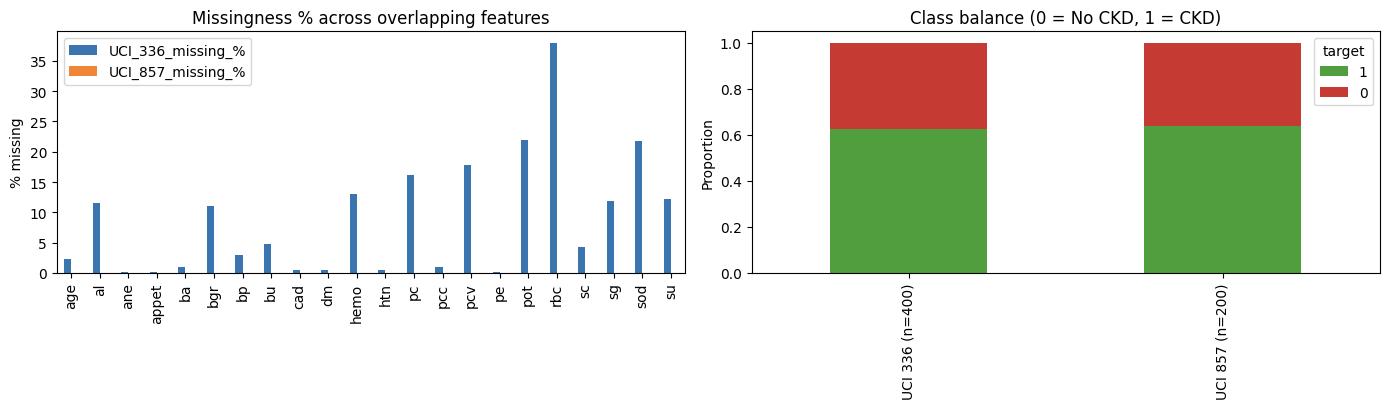

In [4]:
miss_336 = (df336[SHARED_FEATURES].isna().mean() * 100).round(1)
miss_857 = (df857[SHARED_FEATURES].isna().mean() * 100).round(1)
eda_miss = pd.DataFrame({"UCI_336_missing_%": miss_336, "UCI_857_missing_%": miss_857})
display(eda_miss)
eda_miss.to_csv(f"{RES}/05_ckd_missingness_comparison.csv")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
eda_miss.plot.bar(ax=ax[0], color=["#3b75af", "#ef8636"])
ax[0].set_title("Missingness % across overlapping features")
ax[0].set_ylabel("% missing")

pd.DataFrame({
    "UCI 336 (n=400)": df336["target"].value_counts(normalize=True),
    "UCI 857 (n=200)": df857["target"].value_counts(normalize=True),
}).T.plot.bar(stacked=True, ax=ax[1], color=["#519e3e", "#c53a32"])
ax[1].set_title("Class balance (0 = No CKD, 1 = CKD)")
ax[1].set_ylabel("Proportion")
plt.tight_layout()
plt.savefig(f"{RES}/05_ckd_eda.png", dpi=150)
plt.show()

## 2. Primary CKD Model Training, Cross-Validation & Calibration (`UCI 336`)

- **Leakage-free preprocessing:** `SimpleImputer(strategy="median", add_indicator=True)` + `StandardScaler()` encapsulated inside `sklearn.pipeline.Pipeline` so statistics are fit strictly on training folds.
- **Models compared:** `LogReg`, `RandomForest`, and `XGBoost` on an 80/20 stratified patient-level split.
- **Calibration:** Platt scaling (`CalibratedClassifierCV(method="sigmoid", cv=5)`) applied to the top model to ensure trustworthy risk probabilities.

In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import calibration_curve, CalibratedClassifierCV
from sklearn.base import clone
from sklearn.metrics import (roc_auc_score, f1_score, precision_score,
                             recall_score, accuracy_score, brier_score_loss)
from xgboost import XGBClassifier

FEATURES_336 = [c for c in df336.columns if c != "target"]


def make_ckd_prep():
    return Pipeline([
        ("imp", SimpleImputer(strategy="median", add_indicator=True)),
        ("sc", StandardScaler()),
    ])


def get_ckd_models():
    return {
        "LogReg": Pipeline([
            ("prep", make_ckd_prep()),
            ("clf", LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced", random_state=SEED)),
        ]),
        "RandomForest": Pipeline([
            ("prep", make_ckd_prep()),
            ("clf", RandomForestClassifier(n_estimators=400, min_samples_leaf=3,
                                           class_weight="balanced", random_state=SEED, n_jobs=-1)),
        ]),
        "XGBoost": Pipeline([
            ("prep", make_ckd_prep()),
            ("clf", XGBClassifier(n_estimators=250, max_depth=3, learning_rate=0.05,
                                  subsample=0.8, colsample_bytree=0.8,
                                  eval_metric="logloss", random_state=SEED)),
        ]),
    }


tr_idx, te_idx = train_test_split(
    np.arange(len(df336)), test_size=0.2, random_state=SEED, stratify=df336["target"]
)
Xtr, ytr = df336.iloc[tr_idx][FEATURES_336], df336.iloc[tr_idx]["target"]
Xte, yte = df336.iloc[te_idx][FEATURES_336], df336.iloc[te_idx]["target"]

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
scoring = {"auroc": "roc_auc", "f1": "f1", "precision": "precision", "recall": "recall", "accuracy": "accuracy"}

cv_rows = []
for name, m in get_ckd_models().items():
    s = cross_validate(m, Xtr, ytr, cv=cv, scoring=scoring)
    cv_rows.append({"model": name, **{k: f"{s[f'test_{k}'].mean():.3f} ± {s[f'test_{k}'].std():.3f}" for k in scoring}})
cv_table = pd.DataFrame(cv_rows).set_index("model")
print("UCI 336 — 5-Fold Cross-Validation:")
display(cv_table)
cv_table.to_csv(f"{RES}/05_ckd_336_cv_results.csv")

models_336, test_prob_336, rows = {}, {}, []
for name, m in get_ckd_models().items():
    m.fit(Xtr, ytr)
    p = m.predict_proba(Xte)[:, 1]
    pred = (p >= 0.5).astype(int)
    models_336[name], test_prob_336[name] = m, p
    rows.append({
        "model": name,
        "auroc": roc_auc_score(yte, p),
        "f1": f1_score(yte, pred),
        "precision": precision_score(yte, pred),
        "recall": recall_score(yte, pred),
        "accuracy": accuracy_score(yte, pred),
        "brier": brier_score_loss(yte, p),
    })

test_table = pd.DataFrame(rows).set_index("model").round(3)
print("\nUCI 336 — Held-Out Test Split:")
display(test_table)
test_table.to_csv(f"{RES}/05_ckd_336_test_results.csv")

BEST_CKD = test_table["auroc"].idxmax()
cal_ckd = CalibratedClassifierCV(clone(models_336[BEST_CKD]), method="sigmoid", cv=5).fit(Xtr, ytr)
p_raw = test_prob_336[BEST_CKD]
p_cal = cal_ckd.predict_proba(Xte)[:, 1]
print(f"\nBest CKD model: {BEST_CKD} | Brier raw = {brier_score_loss(yte, p_raw):.4f} -> calibrated = {brier_score_loss(yte, p_cal):.4f}")

UCI 336 — 5-Fold Cross-Validation:


,auroc,f1,precision,recall,accuracy
model,,,,,
LogReg,1.000 ± 0.000,0.997 ± 0.005,1.000 ± 0.000,0.995 ± 0.010,0.997 ± 0.006
RandomForest,1.000 ± 0.000,0.995 ± 0.006,0.990 ± 0.012,1.000 ± 0.000,0.994 ± 0.008
XGBoost,0.999 ± 0.001,0.990 ± 0.009,0.990 ± 0.012,0.990 ± 0.012,0.988 ± 0.012



UCI 336 — Held-Out Test Split:


,auroc,f1,precision,recall,accuracy,brier
model,,,,,,
LogReg,0.987,0.969,1.0,0.94,0.962,0.032
RandomForest,1.000,1.000,1.0,1.00,1.000,0.010
XGBoost,1.000,1.000,1.0,1.00,1.000,0.001



Best CKD model: RandomForest | Brier raw = 0.0103 -> calibrated = 0.0044


## 3. Cross-Dataset Generalization (`UCI 336` $\leftrightarrow$ `UCI 857`) & Missing-Data Robustness

- **Cross-dataset test (Week 4 Deliverable):** Train exclusively on `UCI 336` using the overlapping clinical features and test zero-shot on `UCI 857` (and vice versa). Because `UCI 857` comes from a separate hospital cohort and uses discretized clinical intervals, this strictly tests domain shift and feature harmonization.
- **Panel-aware & random missingness:** Evaluates how AUROC degrades as 0% to 60% of inputs are hidden at test time.

Cross-Dataset Generalization (Overlapping Features Only):


,train_dataset,test_dataset,model,auroc,f1,accuracy,brier
0,UCI_336,UCI_857,LogReg,1.000,0.924,0.910,0.066
1,UCI_336,UCI_857,RandomForest,1.000,0.977,0.970,0.058
2,UCI_336,UCI_857,XGBoost,0.999,0.985,0.980,0.018
3,UCI_857,UCI_336,LogReg,0.988,0.789,0.667,0.272
4,UCI_857,UCI_336,RandomForest,1.000,0.992,0.990,0.016
5,UCI_857,UCI_336,XGBoost,0.998,0.984,0.980,0.016


,LogReg,RandomForest,XGBoost
inputs_hidden,,,
0%,0.987,1.000,1.000
10%,0.968,1.000,1.000
20%,0.971,1.000,0.999
30%,0.964,0.994,0.992
40%,0.952,0.990,0.983
50%,0.928,0.982,0.973
60%,0.894,0.951,0.936


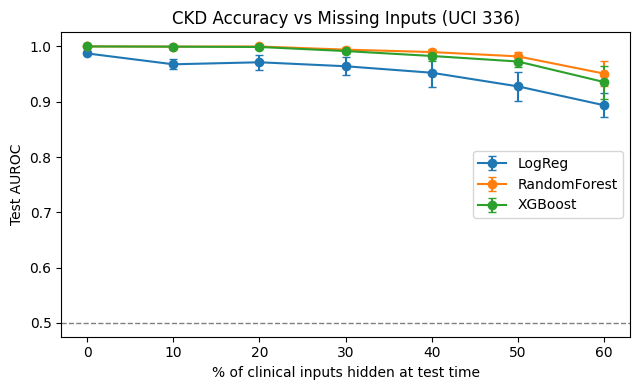

In [6]:
cross_rows = []
for train_name, tr_df, test_name, te_df in [
    ("UCI_336", df336, "UCI_857", df857),
    ("UCI_857", df857, "UCI_336", df336),
]:
    for m_name, m in get_ckd_models().items():
        m.fit(tr_df[SHARED_FEATURES], tr_df["target"])
        p = m.predict_proba(te_df[SHARED_FEATURES])[:, 1]
        pred = (p >= 0.5).astype(int)
        cross_rows.append({
            "train_dataset": train_name,
            "test_dataset": test_name,
            "model": m_name,
            "auroc": round(roc_auc_score(te_df["target"], p), 3),
            "f1": round(f1_score(te_df["target"], pred), 3),
            "accuracy": round(accuracy_score(te_df["target"], pred), 3),
            "brier": round(brier_score_loss(te_df["target"], p), 3),
        })

cross_table = pd.DataFrame(cross_rows)
print("Cross-Dataset Generalization (Overlapping Features Only):")
display(cross_table)
cross_table.to_csv(f"{RES}/05_ckd_cross_dataset_generalization.csv", index=False)

# Missing-data robustness on UCI 336 held-out test split
rng = np.random.default_rng(SEED)
levels = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6]
robust, robust_sd = {n: [] for n in models_336}, {n: [] for n in models_336}

for frac in levels:
    aucs = {n: [] for n in models_336}
    for _ in range(10 if frac > 0 else 1):
        Xm = Xte.copy().astype(float)
        Xm = Xm.mask(rng.random(Xm.shape) < frac)
        for n, m in models_336.items():
            aucs[n].append(roc_auc_score(yte, m.predict_proba(Xm)[:, 1]))
    for n in models_336:
        robust[n].append(np.mean(aucs[n]))
        robust_sd[n].append(np.std(aucs[n]))

rob_df = pd.DataFrame(robust, index=[f"{int(l*100)}%" for l in levels]).round(3)
rob_df.index.name = "inputs_hidden"
display(rob_df)
rob_df.to_csv(f"{RES}/05_ckd_missing_robustness.csv")

plt.figure(figsize=(6.5, 4))
for n in models_336:
    plt.errorbar([l * 100 for l in levels], robust[n], yerr=robust_sd[n], marker="o", label=n, capsize=3)
plt.axhline(0.5, color="grey", ls="--", lw=1)
plt.xlabel("% of clinical inputs hidden at test time")
plt.ylabel("Test AUROC")
plt.title("CKD Accuracy vs Missing Inputs (UCI 336)")
plt.legend(); plt.tight_layout()
plt.savefig(f"{RES}/05_ckd_missing_robustness.png", dpi=150)
plt.show()

## 4. Sub-Modality Conflict Detection (Labs vs. History/Symptoms), SHAP & Shared JSON Contract

To keep CKD completely aligned with the multimodal conflict and reliability framework:
- **Laboratory Sub-Model:** Trained on renal & blood chemistry markers (`sc`, `bu`, `hemo`, `pcv`, `sg`, `al`, `su`, `bgr`, `sod`, `pot`, `wc`, `rc`, `rbc`, `pc`, `pcc`, `ba`).
- **Clinical History & Symptoms Sub-Model:** Trained on patient demographics, comorbidities, and physical symptoms (`age`, `bp`, `htn`, `dm`, `cad`, `appet`, `pe`, `ane`).
- When both panels are present and point in opposite directions ($p_{\text{lab}} \ge 0.6$ vs. $p_{\text{hist}} \le 0.4$ or vice versa), `ckd_assess()` flags a `lab_vs_history_disagreement` conflict, lowers reliability, and recommends confirmatory renal workup.

Sub-modality Test AUROCs (UCI 336): Lab panel = 1.0 | History/Symptoms = 0.993


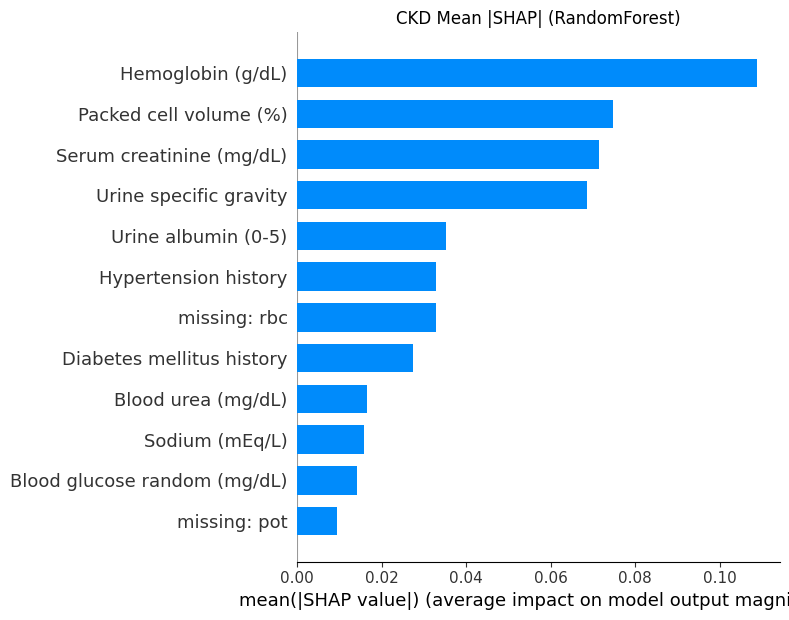

In [7]:
import shap

LAB_COLS  = [c for c in ["sc", "bu", "hemo", "pcv", "sg", "al", "su", "bgr", "sod", "pot", "wc", "rc", "rbc", "pc", "pcc", "ba"] if c in FEATURES_336]
HIST_COLS = [c for c in ["age", "bp", "htn", "dm", "cad", "appet", "pe", "ane"] if c in FEATURES_336]

lab_model  = CalibratedClassifierCV(clone(models_336[BEST_CKD]), method="sigmoid", cv=5).fit(Xtr[LAB_COLS], ytr)
hist_model = CalibratedClassifierCV(clone(models_336[BEST_CKD]), method="sigmoid", cv=5).fit(Xtr[HIST_COLS], ytr)

print("Sub-modality Test AUROCs (UCI 336):",
      "Lab panel =", round(roc_auc_score(yte, lab_model.predict_proba(Xte[LAB_COLS])[:, 1]), 3),
      "| History/Symptoms =", round(roc_auc_score(yte, hist_model.predict_proba(Xte[HIST_COLS])[:, 1]), 3))

# Dynamic SHAP matched to BEST_CKD
best_pipe = models_336[BEST_CKD]
prep, clf = best_pipe.named_steps["prep"], best_pipe.named_steps["clf"]
feat_names = [n.replace("imp__", "").replace("missingindicator_", "missing: ")
              for n in prep.get_feature_names_out(FEATURES_336)]

Xtr_t = prep.transform(Xtr[FEATURES_336])
Xte_t = prep.transform(Xte[FEATURES_336])

if BEST_CKD in ("XGBoost", "RandomForest"):
    explainer = shap.TreeExplainer(clf)
    raw_sv = explainer.shap_values(Xte_t)
    if isinstance(raw_sv, list):
        sv, base_val = raw_sv[1], explainer.expected_value[1]
    elif raw_sv.ndim == 3:
        sv, base_val = raw_sv[:, :, 1], explainer.expected_value[1]
    else:
        sv, base_val = raw_sv, explainer.expected_value
else:
    explainer = shap.LinearExplainer(clf, Xtr_t)
    sv, base_val = explainer.shap_values(Xte_t), explainer.expected_value

FRIENDLY_CKD = {
    "age": "Age (years)", "bp": "Blood pressure (diastolic, mmHg)", "sg": "Urine specific gravity",
    "al": "Urine albumin (0-5)", "su": "Urine sugar (0-5)", "rbc": "Red blood cells in urine",
    "pc": "Pus cells in urine", "pcc": "Pus cell clumps", "ba": "Bacteria in urine",
    "bgr": "Blood glucose random (mg/dL)", "bu": "Blood urea (mg/dL)", "sc": "Serum creatinine (mg/dL)",
    "sod": "Sodium (mEq/L)", "pot": "Potassium (mEq/L)", "hemo": "Hemoglobin (g/dL)",
    "pcv": "Packed cell volume (%)", "wc": "White blood cell count", "rc": "Red blood cell count",
    "htn": "Hypertension history", "dm": "Diabetes mellitus history", "cad": "Coronary artery disease",
    "appet": "Poor appetite", "pe": "Pedal edema", "ane": "Anemia",
}
labels_ckd = [FRIENDLY_CKD.get(n, n) for n in feat_names]

plt.figure()
shap.summary_plot(sv, Xte_t, feature_names=labels_ckd, plot_type="bar", show=False, max_display=12)
plt.title(f"CKD Mean |SHAP| ({BEST_CKD})"); plt.tight_layout()
plt.savefig(f"{RES}/05_ckd_shap_global_bar.png", dpi=150, bbox_inches="tight"); plt.show()

CKD_MISSING_TO_TEST = {
    "sc":   "Serum creatinine & estimated GFR (eGFR)",
    "bu":   "Blood urea nitrogen (BUN) panel",
    "al":   "Urine dipstick & albumin-to-creatinine ratio (uACR)",
    "sg":   "Urinalysis (specific gravity & microscopy)",
    "hemo": "Complete blood count (hemoglobin & PCV)",
    "pcv":  "Complete blood count (hemoglobin & PCV)",
    "bgr":  "Fasting / random blood glucose & HbA1c",
    "sod":  "Serum electrolytes (sodium & potassium)",
    "pot":  "Serum electrolytes (sodium & potassium)",
    "bp":   "Resting blood pressure measurement",
}


def ckd_suggest(missing, conflict, risk):
    out = []
    if conflict:
        out.append({"test": "Repeat renal function panel (eGFR, serum creatinine) and clinical review",
                    "reason": "Laboratory markers and clinical history/symptoms disagree"})
    if risk >= 0.5:
        out.append({"test": "Urine albumin-to-creatinine ratio (uACR) and renal ultrasound",
                    "reason": f"Elevated CKD risk estimate ({risk:.2f})"})
    for col in missing:
        t = CKD_MISSING_TO_TEST.get(col)
        if t:
            out.append({"test": t, "reason": f"{col} not available"})
    uniq, seen = [], set()
    for item in out:
        if item["test"] not in seen:
            uniq.append(item); seen.add(item["test"])
    return uniq[:5]


def ckd_explanation(row_df, top_k=4):
    xt = prep.transform(row_df[FEATURES_336])
    raw_s = explainer.shap_values(xt)
    if isinstance(raw_s, list):
        s = raw_s[1][0]
    elif raw_s.ndim == 3:
        s = raw_s[0, :, 1]
    else:
        s = raw_s[0]
    out = []
    for j in np.argsort(-np.abs(s))[:top_k]:
        n = feat_names[j]
        col = n.replace("missing: ", "") if n.startswith("missing: ") else n
        v = row_df[col].iloc[0] if col in FEATURES_336 else np.nan
        out.append({
            "feature": labels_ckd[j],
            "value": None if pd.isna(v) else float(v),
            "shap": round(float(s[j]), 3),
            "direction": "raises risk" if s[j] > 0 else "lowers risk",
        })
    return out


def ckd_assess(row_df, conflict_margin=0.1):
    """Returns the exact 9-key shared JSON contract for Chronic Kidney Disease."""
    row = row_df.reindex(columns=FEATURES_336).astype(float)
    pf = float(np.clip(cal_ckd.predict_proba(row)[:, 1][0], 1e-4, 1 - 1e-4))
    p_lab = float(np.clip(lab_model.predict_proba(row[LAB_COLS])[:, 1][0], 1e-4, 1 - 1e-4))
    p_hist = float(np.clip(hist_model.predict_proba(row[HIST_COLS])[:, 1][0], 1e-4, 1 - 1e-4))

    miss = [c for c in FEATURES_336 if pd.isna(row[c].iloc[0])]
    has_labs = any(not pd.isna(row[c].iloc[0]) for c in LAB_COLS)
    has_hist = any(not pd.isna(row[c].iloc[0]) for c in HIST_COLS)

    conflict = bool(has_labs and has_hist and (
        (p_lab >= 0.5 + conflict_margin and p_hist <= 0.5 - conflict_margin) or
        (p_hist >= 0.5 + conflict_margin and p_lab <= 0.5 - conflict_margin)
    ))

    d = abs(p_lab - p_hist) if (has_labs and has_hist) else 0.25
    m = len(miss) / len(FEATURES_336)
    u = 1.0 - abs(2.0 * pf - 1.0)
    rel_score = float(np.clip(1.0 - (0.4 * d + 0.3 * m + 0.3 * u), 0.0, 1.0))
    rel_level = "High" if rel_score >= 0.7 else ("Moderate" if rel_score >= 0.5 else "Low")

    reasons = []
    if conflict:
        reasons.append("Laboratory markers and clinical history/symptoms point in opposite directions")
    if m > 0.3:
        reasons.append(f"{len(miss)} of {len(FEATURES_336)} renal/clinical inputs are missing")
    if u > 0.6:
        reasons.append("Predicted probability is close to 0.5")
    if not reasons:
        reasons.append("Laboratory markers and clinical history agree with high input completeness")

    return {
        "disease": "ckd",
        "risk": round(pf, 3),
        "reliability": rel_level,
        "reliability_score": round(rel_score, 3),
        "reliability_reasons": reasons,
        "missing_inputs": miss,
        "conflicts": ([{"type": "lab_vs_history_disagreement",
                        "detail": f"Lab sub-model risk {p_lab:.2f} vs clinical history risk {p_hist:.2f}"}] if conflict else []),
        "suggested_investigations": ckd_suggest(miss, conflict, pf),
        "explanation": {
            "clinical_top_factors": ckd_explanation(row),
            "risk_components": {"lab_panel": round(p_lab, 3), "history_symptoms": round(p_hist, 3)},
        },
        "similar_cases": [],
        "disclaimer": "Decision support only. Not a diagnosis. Suggestions are rule-based and need clinician review.",
    }

In [8]:
joblib.dump({
    "model": cal_ckd,
    "lab_model": lab_model,
    "hist_model": hist_model,
    "raw_models": models_336,
    "best": BEST_CKD,
    "features": FEATURES_336,
    "lab_cols": LAB_COLS,
    "hist_cols": HIST_COLS,
    "shared_features": SHARED_FEATURES,
    "Xtr_background": Xtr_t[:100],
}, f"{MODEL_DIR}/ckd_models.joblib")

# Generate 3 demonstration JSON blocks on held-out test patients
high_i = int(np.argmax(p_cal))
low_i  = int(np.argmin(p_cal))

# Synthetic incomplete case (mask 50% of inputs on a test patient)
incomplete_row = Xte.iloc[[high_i]].copy()
incomplete_row.iloc[0, ::2] = np.nan

examples_ckd = {
    "1_high_risk_ckd": ckd_assess(Xte.iloc[[high_i]]),
    "2_low_risk_ckd": ckd_assess(Xte.iloc[[low_i]]),
    "3_incomplete_inputs": ckd_assess(incomplete_row),
}
json.dump(examples_ckd, open(f"{RES}/05_ckd_example_api_blocks.json", "w"), indent=2)
print("Saved ckd_models.joblib and 05_ckd_example_api_blocks.json")
print(json.dumps(examples_ckd["1_high_risk_ckd"], indent=2))

Saved ckd_models.joblib and 05_ckd_example_api_blocks.json
{
  "disease": "ckd",
  "risk": 0.984,
  "reliability": "High",
  "reliability_score": 0.987,
  "reliability_reasons": [
    "Laboratory markers and clinical history agree with high input completeness"
  ],
  "missing_inputs": [],
  "conflicts": [],
  "suggested_investigations": [
    {
      "test": "Urine albumin-to-creatinine ratio (uACR) and renal ultrasound",
      "reason": "Elevated CKD risk estimate (0.98)"
    }
  ],
  "explanation": {
    "clinical_top_factors": [
      {
        "feature": "Hemoglobin (g/dL)",
        "value": 8.1,
        "shap": 0.098,
        "direction": "raises risk"
      },
      {
        "feature": "Packed cell volume (%)",
        "value": 23.0,
        "shap": 0.072,
        "direction": "raises risk"
      },
      {
        "feature": "Urine specific gravity",
        "value": 1.015,
        "shap": 0.071,
        "direction": "raises risk"
      },
      {
        "feature": "Serum crea